In [1]:
import os
import sys
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.image as mpimg
import pandas as pd
%matplotlib inline
scripts = 'Scripts'
import seaborn as sns
import glob
import importlib
sys.path.append(scripts)
import fastQHandling
import BLASTanalysis
import mutCalling
import scipy
from scipy import stats
from statsmodels.stats import multitest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import numpy as np
import math
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats

from scipy import stats
from statsmodels.stats import multitest
from IPython.display import IFrame    
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

#multiprocessing for mapping to speed things up a bit
from multiprocessing import Pool
numProcessors = 4
import subprocess
#some parameters for plotting

#Superdirectory containing fastq files for all experiments
sequenceDirectory = "Sequencing/totalRNAseq"
#links to precompiled STAR indices
genome = 'Database/human_WSN/human_445'
GTF = 'Database/human_WSN/human_445.gtf'
figureDirectory = 'Figures/totalRNAseq'
if not os.path.isdir(figureDirectory):
    os.mkdir(figureDirectory)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.size': 16, 'axes.titlesize':'medium',})
sns.set_style("white")
sns.set_style("ticks")
from IPython.core.display import HTML
HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

colormap = 'colorblind'
colors = sns.color_palette(colormap, 8)
segments = ['PB2_vRNA','PB1_vRNA','PA_vRNA','HA_vRNA','NP_vRNA','NA_vRNA','M_vRNA','NS_vRNA']
mRNAs = [segment.split('_')[0] + '_mRNA' for segment in segments]
fluColors = {}
for color, segment in enumerate(segments):
    fluColors[segment] = colors[color]
typeI = ['IFNB1', 'IFNA1', 'IFNA2', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8','IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17' ]
typeIII = ['IL28A', 'IL28B', 'IL29']
adapterFile = os.path.join('Database','human_WSN','adapter.fa')

#to correct for absolute measurements of counts

vRNALengths = {'PB2_vRNA':2341,'PB1_vRNA':795, 'PA_vRNA':2233, 'HA_vRNA':1775, 'NP_vRNA':1565,
            'NA_vRNA':1409, 'M_vRNA':1027, 'NS_vRNA':890}

mRNALengths = {'PB2_mRNA':2341,'PB1_mRNA':795, 'PA_mRNA':2233, 'HA_mRNA':1775, 'NP_mRNA':1565,
            'NA_mRNA':1409, 'M_mRNA':1027, 'NS_mRNA':890}
specificISG = ['DTX3L','IFI27','IFI6','IFIT1','IFIT3','IRF7','ISG15','MX1','OAS3','PARP14','PARP9','SAMD9']

# Alignment

In [3]:
experiments = []
for file in glob.glob(os.path.join(sequenceDirectory, '*fastq.gz')):
    sampleType,replicate,read,stuff = os.path.basename(file).split('_')
    experiments += [pd.DataFrame({'experiment':[sampleType], 'replicate':[replicate],
                                  'read_pair':[read], 
                                  'file_name':[file],})]
experiments = pd.concat(experiments).reset_index().drop(columns=['index'])
experiments.set_index(['experiment','replicate']).sort_values(by=['experiment','replicate','read_pair'])   

read_pair  \
experiment   replicate             
PB1-U16A     1                R1   
             1                R2   
             2                R1   
             2                R2   
             3                R1   
             3                R2   
PB1-U20A     1                R1   
             1                R2   
             2                R1   
             2                R2   
             3                R1   
             3                R2   
PB1-U20A-BAL 1                R1   
             1                R2   
             2                R1   
             2                R2   
             3                R1   
             3                R2   

                                                                file_name  
experiment   replicate                                                     
PB1-U16A     1          Sequencing/totalRNAseq/PB1-U16A_1_R1_001.fastq.gz  
             1          Sequencing/totalRNAseq/PB1-U16A_1_R2_001.fastq.gz  
             2          Sequencing/totalRNAseq/PB1-U16A_2_R1_001.fastq.gz  
             2          Sequencing/totalRNAseq/PB1-U16A_2_R2_001.fastq.gz  
             3          Sequencing/totalRNAseq/PB1-U16A_3_R1_001.fastq.gz  
             3          Sequencing/totalRNAseq/PB1-U16A_3_R2_001.fastq.gz  
PB1-U20A     1          Sequencing/totalRNAseq/PB1-U20A_1_R1_001.fastq.gz  
             1          Sequencing/totalRNAseq/PB1-U20A_1_R2_001.fastq.gz  
             2          Sequencing/totalRNAseq/PB1-U20A_2_R1_001.fastq.gz  
             2          Sequencing/totalRNAseq/PB1-U20A_2_R2_001.fastq.gz  
             3          Sequencing/totalRNAseq/PB1-U20A_3_R1_001.fastq.gz  
             3          Sequencing/totalRNAseq/PB1-U20A_3_R2_001.fastq.gz  
PB1-U20A-BAL 1          Sequencing/totalRNAseq/PB1-U20A-BAL_1_R1_001.f...  
             1          Sequencing/totalRNAseq/PB1-U20A-BAL_1_R2_001.f...  
             2          Sequencing/totalRNAseq/PB1-U20A-BAL_2_R1_001.f...  
             2          Sequencing/totalRNAseq/PB1-U20A-BAL_2_R2_001.f...  
             3          Sequencing/totalRNAseq/PB1-U20A-BAL_3_R1_001.f...  
             3          Sequencing/totalRNAseq/PB1-U20A-BAL_3_R2_001.f...

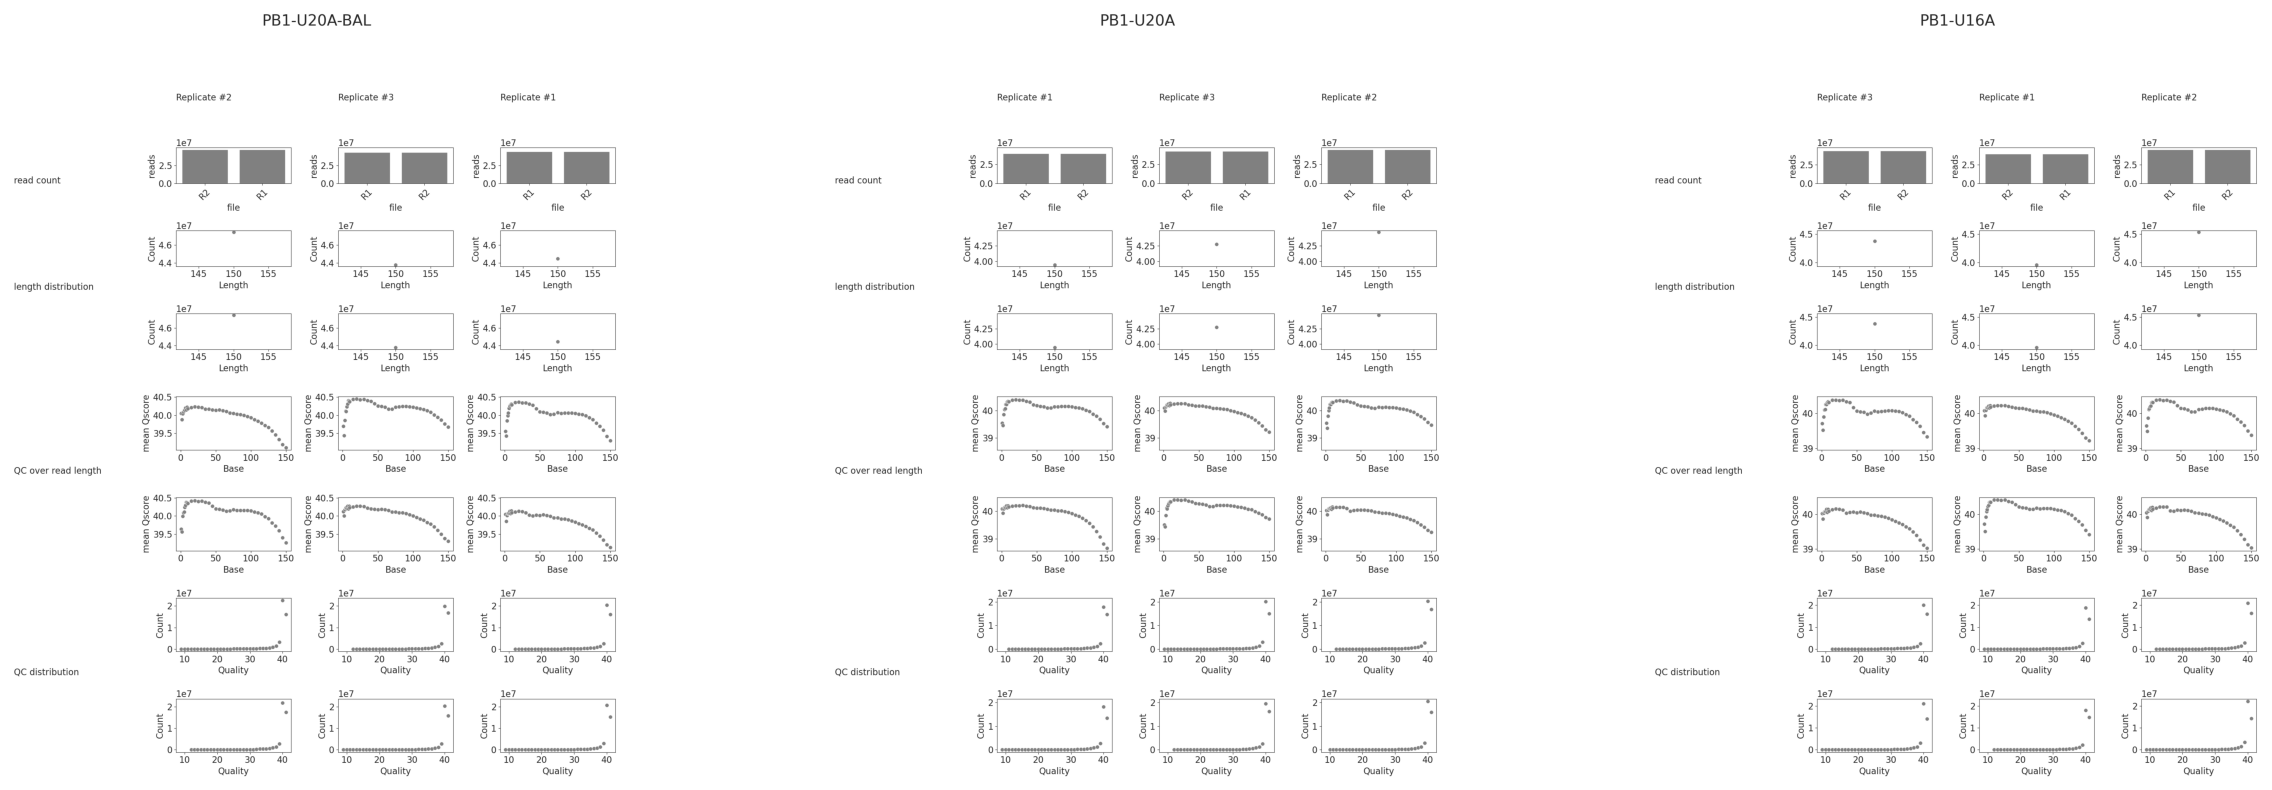

In [30]:

def fastQC(tupleArgument):
    sampleName = tupleArgument[0]
    reads = tupleArgument[1]
    return {sampleName:fastQHandling.fastQCreport(sampleName=sampleName, reads=reads)}
figsDisplay = []
for experiment in set(experiments.experiment):
    reports = []
    results = {}
    samples = {}
    for index, row in experiments[(experiments.experiment == experiment)].iterrows():
        sample = ''.join(['Replicate #',str(row.replicate)])
        read = row.file_name
        readName = row.read_pair
        if sample not in samples.keys():
            samples[sample] = {readName:read}
        else:
            samples[sample][readName] = read
    popList = [(sample, samples[sample]) for sample in list(samples.keys())]
    while len(popList) > 0:
        with Pool(processes = numProcessors) as p:
            reports += p.map(fastQC, [popList.pop() for i in range(numProcessors) if len(popList) != 0])
    reports = {key:value for dictionary in reports for key, value in dictionary.items()} 
    a = fastQHandling.graphAllTheThings(data=reports, title=experiment)
    #pdf for publication
    plt.savefig(sequenceDirectory + '/' +  experiment + '_sequenceQC.pdf', format='pdf', bbox_inches = "tight")
    #png for showing here
    plt.savefig(sequenceDirectory + '/' +  experiment + '_sequenceQC.png', format='png', bbox_inches = "tight")
    plt.close()
    figsDisplay += [sequenceDirectory + '/' +  experiment + '_sequenceQC.png']
width = 10 * len(figsDisplay)
g = plt.figure(1, (width, 10))
spec = g.add_gridspec(ncols= len(figsDisplay),nrows=1)
for column, fig in enumerate(figsDisplay):
    ax = g.add_subplot(spec[0,column])
    img=mpimg.imread(fig)
    ax.imshow(img)
    ax.axis('off')


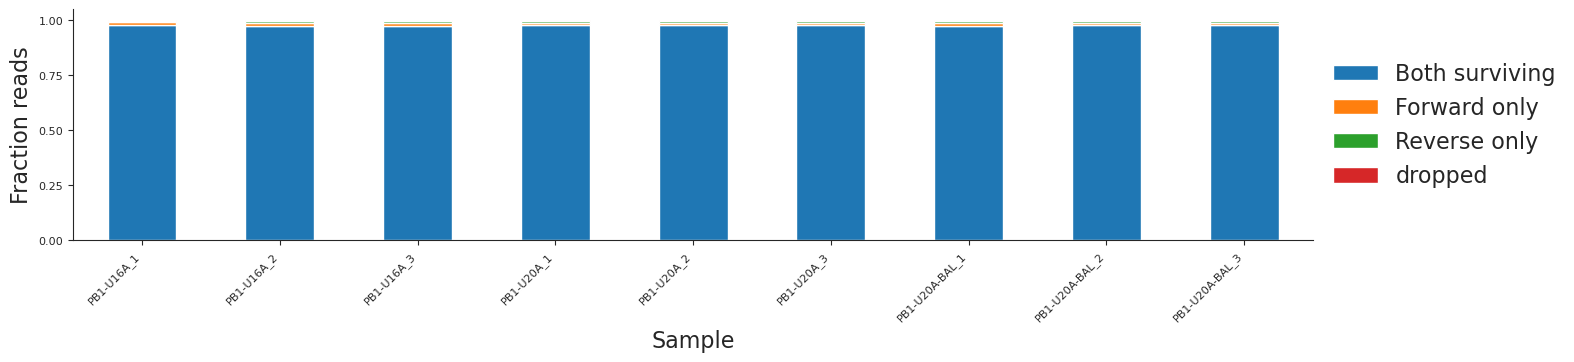

In [31]:
#list comprehension to get reports on trimming statistics. Using baseline recommendations of program creators.
#Can overwrite if need be. Does not rerun if already run in past, only grabs statistics. Pass rerun=True, if overwrite
#is desired.
importlib.reload(fastQHandling)
for experiment in set(experiments.experiment):
    if not os.path.isdir('/'.join([sequenceDirectory, 'trimmed_reads'])):
        os.mkdir('/'.join([sequenceDirectory, 'trimmed_reads']))
rows = experiments.sort_values(['experiment','replicate','read_pair']).groupby(['experiment', 'replicate']).file_name.apply(list).reset_index().iterrows()
stats = pd.concat([fastQHandling.trimCommandPaired(read1=row[1].file_name[0], 
                           read2= row[1].file_name[1],
                           outDirectory='/'.join([sequenceDirectory, 'trimmed_reads']),
                            adapterFile= adapterFile,
                            sampleName = ''.join([row[1].experiment,'_',str(row[1].replicate)]),
                          threads = numProcessors) for row in rows]).set_index('Sample')
#return raw numbers from above as they are generally more useful, but go ahead and collapse to percentages here
stats=stats.div(stats['Input read pairs'], axis=0).drop(columns=['Input read pairs'])
ax = stats.loc[:,['Both surviving', 'Forward only', 'Reverse only', 'dropped']].plot.bar(stacked=True,figsize=(16,3), fontsize=8)
sns.despine()
ax.legend( loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.xticks(rotation=45,horizontalalignment="right")
plt.ylabel('Fraction reads', fontsize=16)
plt.savefig(sequenceDirectory + '/trimming_statistics.pdf', format='pdf', bbox_inches = "tight")


In [5]:
outDirectory = os.path.join('Results','totalRNAseq','alignment')
if not os.path.isdir(os.path.join('Results','totalRNAseq')):
    os.mkdir(os.path.join('Results','totalRNAseq'))
if not os.path.isdir(outDirectory):
    os.mkdir(outDirectory)
rows = experiments.sort_values(['experiment','replicate','read_pair']).groupby(['experiment', 'replicate']).file_name.apply(list).reset_index().iterrows()
for row in rows:
    experiment = row[1].experiment
    replicate = row[1].replicate
    sequences = [os.path.join(sequenceDirectory, 'trimmed_reads', os.path.basename(file)) for file in row[1].file_name]
        
    outprefix = os.path.join(outDirectory,experiment + '_' + str(replicate)) + '_'
    unzippedReads = [file[:-3] for file in sequences]
    for read in sequences:
        unzippedRead = read[:-3]
        !gunzip -c $read > $unzippedRead
    reads = ' '.join(unzippedReads)
    capture = !STAR --runMode alignReads --runThreadN $numProcessors --genomeDir $genome --readFilesIn $reads --outFileNamePrefix $outprefix --outSAMtype BAM Unsorted --outReadsUnmapped Fastx
    logFile =  outprefix + 'terminal.txt'

    with open(logFile, 'w') as outfile:
        for line in capture:
            outfile.write(line + '\n')
    for read in unzippedReads:
        !rm -f $read


"\noutDirectory = os.path.join('Results','totalRNAseq','alignment')\nif not os.path.isdir(os.path.join('Results','totalRNAseq')):\n    os.mkdir(os.path.join('Results','totalRNAseq'))\nif not os.path.isdir(outDirectory):\n    os.mkdir(outDirectory)\nrows = experiments.sort_values(['experiment','replicate','read_pair']).groupby(['experiment', 'replicate']).file_name.apply(list).reset_index().iterrows()\nfor row in rows:\n    experiment = row[1].experiment\n    if experiment.split('-')[0] == 'PB1':\n        genome = genomes['DelVG']\n    else:\n        genome = genomes['WT']\n    replicate = row[1].replicate\n    sequences = [os.path.join(sequenceDirectory, 'trimmed_reads', os.path.basename(file)) for file in row[1].file_name]\n        \n    outprefix = os.path.join(outDirectory,experiment + '_' + str(replicate)) + '_'\n    unzippedReads = [file[:-3] for file in sequences]\n    for read in sequences:\n        unzippedRead = read[:-3]\n        !gunzip -c $read > $unzippedRead\n    reads = 

check polyadenylation or c/ccRNA status of PB1


In [5]:
adjMatch = 'AATTTAGCTTGTCCTTCATG'
adjMatchRev = 'CATGAAGGACAAGCTAAATT'
forwardRead = 'R2'
reverseRead = 'R1'

def reverseComplement(sequence):
    revComp =''
    for char in sequence[::-1]:
        if char == 'A':
            revComp += 'T'
        elif char == 'G':
            revComp += 'C'
        elif char == 'C':
            revComp += 'G'
        elif char == 'T':
            revComp += 'A'
        elif char == 'N':
            revComp += 'N'
    return revComp
if not os.path.isdir(os.path.join('Sequencing','totalRNAseq','3primePB1')):
    os.mkdir(os.path.join('Sequencing','totalRNAseq','3primePB1'))
rows = experiments.sort_values(['experiment','replicate','read_pair']).groupby(['experiment', 'replicate']).file_name.apply(list).reset_index().iterrows()
for row in rows:
    experiment = row[1].experiment
    replicate = row[1].replicate
    sequences = [os.path.join(sequenceDirectory, 'trimmed_reads', os.path.basename(file)) for file in row[1].file_name]
    #always R1 and R2 with sort above.
    currFile = sequences[0]
    outFile = os.path.join('Sequencing','totalRNAseq','3primePB1',experiment + '_' + replicate)
    out1 = outFile +'_R1.fasta'
    out2 = outFile + '_R2.fasta'
    os.system("gunzip -c " + currFile + "| grep -oP \'.{9}(?=CATGAAGGACAAGCTAAATT)\' > " + out1)
    #!gunzip -c $currFile  | grep -oP '.{9}(?=CATGAAGGACAAGCTAAATT)' > $out1
    currFile = sequences[1]
    os.system("gunzip -c " + currFile + " | grep -oP \'AATTTAGCTTGTCCTTCATG\\K.{9}\' > " + out2)




Assessment of retention of mutation in PB1 U16A and PB1 U20A. Use samtools flag to only pull vRNA. Sort PB1, index, and use mpileup.

In this stranded RNAseq, read 2 is forward and read 1 is reverse. The orientation of our mapped genome in this case is (+). So when read 1 is in the (+) orientation, we have vRNA, when (-) we have mRNA.

SAM flag 96 will recover read1 (first in pair, mate reverse strand)
SAM flag 144 will recover read2 (second in pair read reverse strand)
then sort by name as you messed up the interleaving (and I don't think there is a clever way to fix with grep. Small files anyway).

in (+) orientation, in this template, U20A = position 776
U16A = position 780.

alignment files are not position sorted, for HTseq-count below, and I don't think it is worth the time, effort, and space to generate fully sorted files. Hence pulling PB1 reads only using grep rather than sorting and indexing existing bamfiles.

In [9]:
inDirectory = os.path.join('Results','totalRNAseq','alignment')
outDirectory = os.path.join('Results','totalRNAseq','alignment', 'PB1vRNAonly')

if not os.path.isdir(outDirectory):
    os.mkdir(outDirectory)
for file in glob.glob(os.path.join(inDirectory, '*_Aligned.out.bam')):
    sampleName = os.path.basename(file)[:-(len('_Aligned.out.bam'))]
    outfile = os.path.join(outDirectory, sampleName + '.sam')
    !samtools view -H $file > $outfile
    !samtools view -f 96 $file | grep PB1_cRNA >> $outfile
    !samtools view -f 144 $file | grep PB1_cRNA >> $outfile
    finOut = os.path.join(outDirectory, sampleName + '.bam')
    !samtools sort -n $outfile > $finOut
    !rm -f $outfile
    finOutCounts = os.path.join(outDirectory, sampleName + '_bases.tsv')
    mutCalling.positionalData(sortedBamfile = finOut, outfile=finOutCounts, qvalCutoff=30)


In [8]:
finOutCounts

'Results/totalRNAseq/alignment/PB1vRNAonly/PB1-U20A-BAL_2/_bases.tsv'

In [ ]:
then for vRNA should probably go ahead and count mutation frequency, although I can probably just pull this from the bamfile.

# HTseq-count and DDseq

In [29]:
inDirectory = os.path.join('Results','totalRNAseq','alignment')
outDirectory = os.path.join('Results','totalRNAseq','counts')
if not os.path.isdir(outDirectory):
    os.mkdir(outDirectory)
    
for file in glob.glob(os.path.join(inDirectory, '*_Aligned.out.bam')):
    sampleName = os.path.basename(file)[:-(len('_Aligned.out.bam'))]
    outfile = os.path.join(outDirectory, sampleName + '_htseq_counts.tsv')
    !htseq-count -s reverse -f bam $file $GTF > $outfile



100000 GFF lines processed.
200000 GFF lines processed.
300000 GFF lines processed.
400000 GFF lines processed.
500000 GFF lines processed.
600000 GFF lines processed.
700000 GFF lines processed.
767431 GFF lines processed.
100000 alignment record pairs processed.
200000 alignment record pairs processed.
300000 alignment record pairs processed.
400000 alignment record pairs processed.
500000 alignment record pairs processed.
600000 alignment record pairs processed.
700000 alignment record pairs processed.
800000 alignment record pairs processed.
900000 alignment record pairs processed.
1000000 alignment record pairs processed.
1100000 alignment record pairs processed.
1200000 alignment record pairs processed.
1300000 alignment record pairs processed.
1400000 alignment record pairs processed.
1500000 alignment record pairs processed.
1600000 alignment record pairs processed.
1700000 alignment record pairs processed.
1800000 alignment record pairs processed.
1900000 alignment record pair

In [2]:
inDirectory = os.path.join('Results','totalRNAseq','counts')
counts_df =  []
metadata_df = []
for file in glob.glob(os.path.join(inDirectory, '*_htseq_counts.tsv')):
    currData = pd.read_csv(file, sep='\t', names = ['gene','count']).iloc[:-5]
    sampleName = '_'.join((os.path.basename(file)).split('_')[0:2])
    currData['sample'] = sampleName
    condition = sampleName.split('_')[0]
    metaData = pd.DataFrame({'sample':[sampleName], 'condition':[condition]}).set_index('sample')
    currData = currData.pivot_table(index= 'sample' , columns = 'gene', values='count')
    counts_df += [currData]
    metadata_df += [metaData]
counts_df = pd.concat(counts_df).fillna(0)
metadata_df = pd.concat(metadata_df)


                                   

In [14]:
counts_df.to_csv('forGEO.csv')

In [12]:
inDirectory = os.path.join('Results','totalRNAseq','counts')
counts_df =  []
for file in glob.glob(os.path.join(inDirectory, '*_htseq_counts.tsv')):
    currData = pd.read_csv(file, sep='\t', names = ['gene','count']).iloc[:-5]
    sampleName = '_'.join((os.path.basename(file)).split('_')[0:2])
    currData['sample'] = sampleName
    counts_df += [currData]
counts_df = pd.concat(counts_df).fillna(0)



In [10]:
counts_df['sample']

KeyError: 'sample'

In [7]:
pandas.wide_to_long(counts_df, 'gene', i, j, sep='', suffix='\\d+')

AttributeError: 'DataFrame' object has no attribute 'wide_to_long'

In [6]:
inference = DefaultInference(n_cpus=4)
dds = DeseqDataSet(
    counts=counts_df,
    metadata=metadata_df,
    design="~condition",  # compare samples based on the "condition"
    # column ("B" vs "A")
    refit_cooks=True,
    inference=inference,
)

In [7]:
dds.fit_size_factors()

dds.obs["size_factors"]

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.



sample
PB1-U20A-BAL_3    1.093874
PB1-U20A-BAL_1    1.138362
PB1-U16A_2        1.062595
PB1-U20A-BAL_2    1.196168
PB1-U16A_1        0.925376
PB1-U16A_3        0.981093
PB1-U20A_3        0.915551
PB1-U20A_2        0.961433
PB1-U20A_1        0.842631
Name: size_factors, dtype: float64

In [8]:
dds.fit_genewise_dispersions()

dds.var["genewise_dispersions"]

Fitting dispersions...
... done in 3.23 seconds.



gene
1/2-SBSRNA4    4.650350e-02
61E3.4         1.000000e-08
A1BG           1.000000e-08
A1BG-AS1       1.000000e-08
A1CF           1.000000e-08
                   ...     
ZYX            2.368877e-03
ZZEF1          5.062428e-04
ZZZ3           3.316996e-03
psiTPTE22      1.000000e-08
tAKR           1.000000e-08
Name: genewise_dispersions, Length: 25575, dtype: float64

In [9]:
dds.fit_dispersion_trend()
dds.uns["trend_coeffs"]
dds.var["fitted_dispersions"]

Fitting dispersion trend curve...
... done in 0.32 seconds.



gene
1/2-SBSRNA4     0.051812
61E3.4          0.018784
A1BG            0.089501
A1BG-AS1        0.022173
A1CF            0.034493
                 ...    
ZYX             0.001718
ZZEF1           0.001959
ZZZ3            0.002794
psiTPTE22      10.946334
tAKR            0.936727
Name: fitted_dispersions, Length: 25575, dtype: float64

In [10]:
dds.fit_dispersion_prior()
print(
    f"logres_prior={dds.uns['_squared_logres']}, sigma_prior={dds.uns['prior_disp_var']}"
)

logres_prior=0.5957523059053583, sigma_prior=0.25


In [11]:
dds.fit_MAP_dispersions()
dds.var["MAP_dispersions"]
dds.var["dispersions"]

Fitting MAP dispersions...
... done in 3.81 seconds.



gene
1/2-SBSRNA4     0.050624
61E3.4          0.014774
A1BG            0.065696
A1BG-AS1        0.017371
A1CF            0.030066
                 ...    
ZYX             0.001966
ZZEF1           0.001411
ZZZ3            0.002949
psiTPTE22      10.000000
tAKR            0.962204
Name: dispersions, Length: 25575, dtype: float64

In [12]:
dds.fit_LFC()
dds.varm["LFC"]

Fitting LFCs...
... done in 2.28 seconds.



,Intercept,condition[T.PB1-U20A],condition[T.PB1-U20A-BAL]
gene,,,
1/2-SBSRNA4,3.527280,-0.341836,-0.479250
61E3.4,4.357760,-0.004958,-0.039041
A1BG,3.162258,-0.726435,-0.840066
A1BG-AS1,4.100822,-0.141901,0.286934
A1CF,3.945783,-0.725709,-0.163761
...,...,...,...
ZYX,8.936630,0.079635,-0.205052
ZZEF1,8.052551,-0.080075,0.078663
ZZZ3,7.043736,-0.102784,-0.145405


In [13]:
dds.calculate_cooks()
if dds.refit_cooks:
    # Replace outlier counts
    dds.refit()

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.



start with U20A vs U16A

In [14]:
ds = DeseqStats(
    dds,
    contrast=['condition','PB1-U20A','PB1-U16A'],
    alpha=0.05,
    cooks_filter=True,
    independent_filter=True,
)

In [15]:
ds.run_wald_test()
ds.p_values

Running Wald tests...
... done in 8.32 seconds.



gene
1/2-SBSRNA4    0.158972
61E3.4         0.971237
A1BG           0.015633
A1BG-AS1       0.361616
A1CF           0.000354
                 ...   
ZYX            0.033285
ZZEF1          0.019495
ZZZ3           0.044519
psiTPTE22      0.805777
tAKR           0.543475
Length: 25575, dtype: float64

In [16]:
if ds.cooks_filter:
    ds._cooks_filtering()
ds.p_values

gene
1/2-SBSRNA4    0.158972
61E3.4         0.971237
A1BG           0.015633
A1BG-AS1       0.361616
A1CF           0.000354
                 ...   
ZYX            0.033285
ZZEF1          0.019495
ZZZ3           0.044519
psiTPTE22      0.805777
tAKR           0.543475
Length: 25575, dtype: float64

In [17]:
if ds.independent_filter:
    ds._independent_filtering()
else:
    ds._p_value_adjustment()

ds.padj

gene
1/2-SBSRNA4    0.272073
61E3.4         0.982898
A1BG           0.039414
A1BG-AS1       0.506056
A1CF           0.001295
                 ...   
ZYX            0.075517
ZZEF1          0.047624
ZZZ3           0.096714
psiTPTE22           NaN
tAKR                NaN
Name: 10, Length: 25575, dtype: float64

In [18]:
ds.lfc_shrink(coeff="condition[T.PB1-U20A]")


Fitting MAP LFCs...
... done in 3.48 seconds.



In [19]:
ds.summary()
ds.results_df.to_csv('Results/totalRNAseq/U20AvU16A.csv')
results = ds.results_df.reset_index()

Log2 fold change & Wald test p-value: condition PB1-U20A vs PB1-U16A
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene                                                                     
1/2-SBSRNA4    26.419784       -0.311189  0.304829 -1.408538  0.158972   
61E3.4         77.014133       -0.005541  0.177896 -0.036057  0.971237   
A1BG           15.100148       -0.729210  0.454286 -2.417382  0.015633   
A1BG-AS1       64.366936       -0.158579  0.200778 -0.912290  0.361616   
A1CF           40.304301       -0.911270  0.301924 -3.571985  0.000354   
...                  ...             ...       ...       ...       ...   
ZYX          7345.465203        0.112968  0.053544  2.128629  0.033285   
ZZEF1        3146.771562       -0.113834  0.049123 -2.335935  0.019495   
ZZZ3         1057.086735       -0.143560  0.072805 -2.009168  0.044519   
psiTPTE22       0.121360        0.022144  0.456966  0.245878  0.805777   
tAKR            1.420309       -0.062211  0

Now with and without baloxavir. Use PB1-U20A no baloxavir as comparitor to produce nice opposite graphs as below.

In [20]:
ds = DeseqStats(
    dds,
    contrast=['condition','PB1-U20A-BAL','PB1-U20A'],
    alpha=0.05,
    cooks_filter=True,
    independent_filter=True,
)

In [21]:
ds.run_wald_test()
ds.p_values

Running Wald tests...
... done in 1.11 seconds.



gene
1/2-SBSRNA4    5.835530e-01
61E3.4         8.020134e-01
A1BG           7.253789e-01
A1BG-AS1       4.029433e-03
A1CF           5.748208e-03
                   ...     
ZYX            2.910113e-14
ZZEF1          2.957165e-06
ZZZ3           4.047783e-01
psiTPTE22      7.694580e-01
tAKR           1.760226e-01
Length: 25575, dtype: float64

In [22]:
if ds.cooks_filter:
    ds._cooks_filtering()
ds.p_values

gene
1/2-SBSRNA4    5.835530e-01
61E3.4         8.020134e-01
A1BG           7.253789e-01
A1BG-AS1       4.029433e-03
A1CF           5.748208e-03
                   ...     
ZYX            2.910113e-14
ZZEF1          2.957165e-06
ZZZ3           4.047783e-01
psiTPTE22      7.694580e-01
tAKR           1.760226e-01
Length: 25575, dtype: float64

In [23]:
if ds.independent_filter:
    ds._independent_filtering()
else:
    ds._p_value_adjustment()

ds.padj

gene
1/2-SBSRNA4    6.742775e-01
61E3.4         8.551165e-01
A1BG           7.952581e-01
A1BG-AS1       9.129424e-03
A1CF           1.258482e-02
                   ...     
ZYX            2.495503e-13
ZZEF1          1.106703e-05
ZZZ3           5.057399e-01
psiTPTE22               NaN
tAKR           2.568046e-01
Name: 8, Length: 25575, dtype: float64

In [24]:
ds.lfc_shrink(coeff="condition[T.PB1-U20A-BAL]")


Fitting MAP LFCs...
... done in 3.44 seconds.



In [25]:
ds.summary()
ds.results_df.to_csv('Results/totalRNAseq/U20A-BALvU20A.csv')
results = ds.results_df.reset_index()

Log2 fold change & Wald test p-value: condition PB1-U20A-BAL vs PB1-U20A
                baseMean  log2FoldChange     lfcSE      stat        pvalue  \
gene                                                                         
1/2-SBSRNA4    26.419784       -0.023181  0.332139 -0.548202  5.835530e-01   
61E3.4         77.014133       -0.040807  0.179438 -0.250742  8.020134e-01   
A1BG           15.100148        0.089565  0.443033 -0.351279  7.253789e-01   
A1BG-AS1       64.366936        0.564479  0.199822  2.875848  4.029433e-03   
A1CF           40.304301        0.864423  0.235295  2.761809  5.748208e-03   
...                  ...             ...       ...       ...           ...   
ZYX          7345.465203       -0.407273  0.053815 -7.602256  2.910113e-14   
ZZEF1        3146.771562        0.227874  0.048344  4.673773  2.957165e-06   
ZZZ3         1057.086735       -0.056779  0.072285 -0.833118  4.047783e-01   
psiTPTE22       0.121360       -1.091428  0.474064 -0.293084  7.69458

# graphing deseq output

Lets make seprate graphs for IFN, ISG, flu mRNA and flu vRNA for the sake of display

In [4]:
ISGlist = pd.read_csv(os.path.join('Database','ISGlist.csv'))
ISGlist = ISGlist[ (ISGlist['log2(FC)'] > 1) & (ISGlist['P-adj'] < 0.1)]['Gene symbol'].tolist()
IFNlist = typeI + typeIII


In [9]:
results[results.gene.isin(IFNlist)].sort_values('log2FoldChange')

,gene,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,logpadj
8666,IFNA5,20.928005,-0.054022,0.268801,-0.274318,7.838401e-01,8.590884e-01,0.065962
8667,IFNA6,0.473356,0.047384,0.440511,0.653768,5.132610e-01,NaN,NaN
8665,IFNA4,0.433209,0.054975,0.405917,0.653889,5.131832e-01,NaN,NaN
8662,IFNA2,8.463204,3.439094,0.792158,4.764868,1.889771e-06,9.805655e-06,5.008523
8812,IL28B,2116.287609,5.421718,0.101791,53.304394,0.000000e+00,3.843753e-304,303.415245
8811,IL28A,2669.979565,5.484118,0.151640,36.247577,1.085016e-287,6.165691e-285,284.210018
8658,IFNA13,14.189055,5.528417,1.009756,5.457408,4.831351e-08,2.999967e-07,6.522883
8672,IFNB1,314.727086,5.901156,0.237395,24.860661,1.983069e-136,2.729198e-134,133.563965
8814,IL29,2057.190586,5.948284,0.164163,36.314715,9.478955e-289,5.566043e-286,285.254453
8661,IFNA17,12.833041,6.219070,1.304562,4.653429,3.264597e-06,1.646411e-05,4.783462


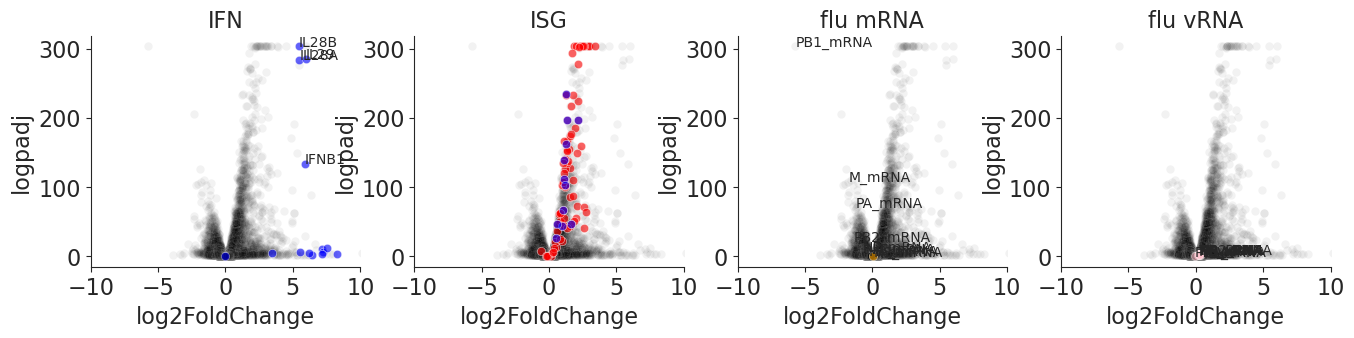

In [5]:
fig, axes =  plt.subplots(1,4, figsize=(16,3), width_ratios = [1,1,1,1])
results = pd.read_csv(os.path.join('Results','totalRNAseq','U20AvU16A.csv'))
#fix infinite values
results.loc[results.padj ==0,'padj'] = results[~(results.padj == 0)].padj.min()
ax = axes[0]
results['logpadj'] = -np.log10(results.padj)
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(typeI + typeIII)].logpadj, x=results[results.gene.isin(typeI + typeIII)].log2FoldChange, alpha=0.6, color='blue', ax=ax)
sns.despine()
ax.set_title('IFN')
for gene in ['IFNB1'] + typeIII:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)

ax = axes[1]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(ISGlist)].logpadj, x=results[results.gene.isin(ISGlist)].log2FoldChange, alpha=0.6, color='red', ax=ax)
sns.scatterplot(y=results[results.gene.isin(specificISG)].logpadj, x=results[results.gene.isin(specificISG)].log2FoldChange, alpha=0.6, color='blue', ax=ax)
ax.set_xlim(-10,10)
sns.despine()
ax.set_title('ISG')

ax = axes[2]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(mRNAs)].logpadj, x=results[results.gene.isin(mRNAs)].log2FoldChange, alpha=0.6, color='orange', ax=ax)
sns.despine()
ax.set_title('flu mRNA')
for gene in mRNAs:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)

ax = axes[3]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(segments)].logpadj, x=results[results.gene.isin(segments)].log2FoldChange, alpha=0.6, color='pink', ax=ax)
sns.despine()
ax.set_title('flu vRNA')
for gene in segments:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)
plt.savefig(os.path.join('Figures','totalRNAseq', 'U20AvU16ADESeq.pdf'), format='pdf', bbox_inches = "tight")


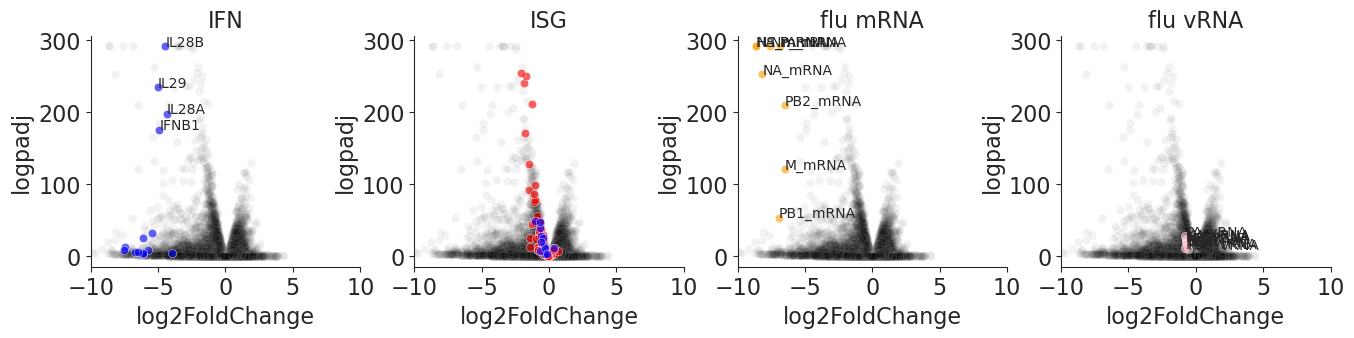

In [4]:
fig, axes =  plt.subplots(1,4, figsize=(16,3), width_ratios = [1,1,1,1])
results = pd.read_csv(os.path.join('Results','totalRNAseq','U20A-BALvU20A.csv'))
#fix infinite values
results.loc[results.padj ==0,'padj'] = results[~(results.padj == 0)].padj.min()
ax = axes[0]
results['logpadj'] = -np.log10(results.padj)
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(typeI + typeIII)].logpadj, x=results[results.gene.isin(typeI + typeIII)].log2FoldChange, alpha=0.6, color='blue', ax=ax)
sns.despine()
ax.set_title('IFN')
for gene in ['IFNB1'] + typeIII:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)

ax = axes[1]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(ISGlist)].logpadj, x=results[results.gene.isin(ISGlist)].log2FoldChange, alpha=0.6, color='red', ax=ax)
sns.scatterplot(y=results[results.gene.isin(specificISG)].logpadj, x=results[results.gene.isin(specificISG)].log2FoldChange, alpha=0.6, color='blue', ax=ax)
ax.set_xlim(-10,10)
sns.despine()
ax.set_title('ISG')

ax = axes[2]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(mRNAs)].logpadj, x=results[results.gene.isin(mRNAs)].log2FoldChange, alpha=0.6, color='orange', ax=ax)
sns.despine()
ax.set_title('flu mRNA')
for gene in mRNAs:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)

ax = axes[3]
sns.scatterplot(data = results, y='logpadj', x='log2FoldChange', alpha=0.05, color='k', rasterized=True, ax=ax)
sns.scatterplot(y=results[results.gene.isin(segments)].logpadj, x=results[results.gene.isin(segments)].log2FoldChange, alpha=0.6, color='pink', ax=ax)
sns.despine()
ax.set_title('flu vRNA')
for gene in segments:
    currFrame = results[results.gene == gene]
    ax.text(currFrame.log2FoldChange.iloc[0], currFrame.logpadj.iloc[0], gene, fontsize=10)
ax.set_xlim(-10,10)
plt.savefig(os.path.join('Figures','totalRNAseq', 'U20A-BALvU20ADESeq.pdf'), format='pdf', bbox_inches = "tight")


# Relative vRNA analysis

overall vRNA assesment as a function of length

In [2]:
inDirectory = os.path.join('Results','totalRNAseq','counts')
counts_df =  []
for file in glob.glob(os.path.join(inDirectory, '*_htseq_counts.tsv')):
    currData = pd.read_csv(file, sep='\t', names = ['gene','count']).iloc[:-5]
    currData = currData[currData.gene.isin(segments)]
    sampleName = '_'.join((os.path.basename(file)).split('_')[0:2])
    currData['replicate'] = sampleName.split('_')[-1]
    condition = sampleName.split('_')[0]
    currData['condition'] = condition
    counts_df += [currData]
counts_df = pd.concat(counts_df).fillna(0)
counts_df['length'] = counts_df.apply(lambda row: vRNALengths[row.gene], axis=1)
counts_df['counts per nt'] = counts_df['count']/counts_df['length']
counts_df = counts_df.merge(counts_df.groupby(['replicate','condition'])['counts per nt'].sum().reset_index().rename(columns = {'counts per nt':'fluSum'}))
counts_df['relative vRNA contribution'] = counts_df['counts per nt']/counts_df.fluSum

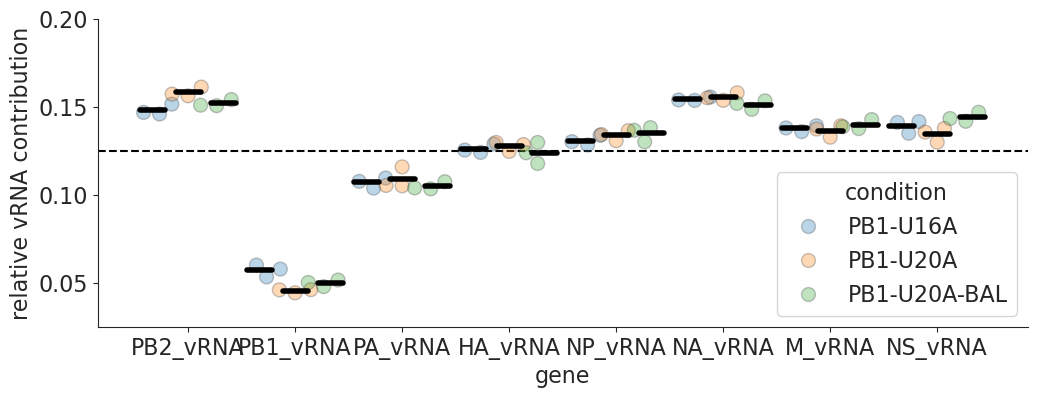

In [3]:
fig, ax = plt.subplots(1,1, figsize=(12,4))
plt.axhline(y=1/8, color = 'k', ls='--')
hue_order = ['PB1-U16A','PB1-U20A','PB1-U20A-BAL']
sns.swarmplot(y='relative vRNA contribution', x='gene', hue='condition',hue_order=hue_order, data=counts_df,        
                dodge=True, linewidth=1, s=10,   zorder=5, order=segments, ax=ax, alpha=0.3)
sns.despine()

plt.ylim(0.025,0.2)
for position, gene in enumerate(segments):
    curr = counts_df[counts_df['gene'] == gene]
    bar = 1/len(hue_order)
    for add, condition in enumerate(hue_order):
        y = curr[(curr.condition == condition)]['relative vRNA contribution'].mean()
        plt.plot([0.5+position-(len(hue_order)-add)*bar+0.05,0.5+position-(len(hue_order)-add)*bar + bar -0.05], [y, y], lw=4, c='k', zorder=9)


cleaner as a barplot, and as 0 has meaning here it is ok to use.

Use one-sample t-test against equivalent distribution to find over/under-represented vRNAs.

corrected pval of 0.01.

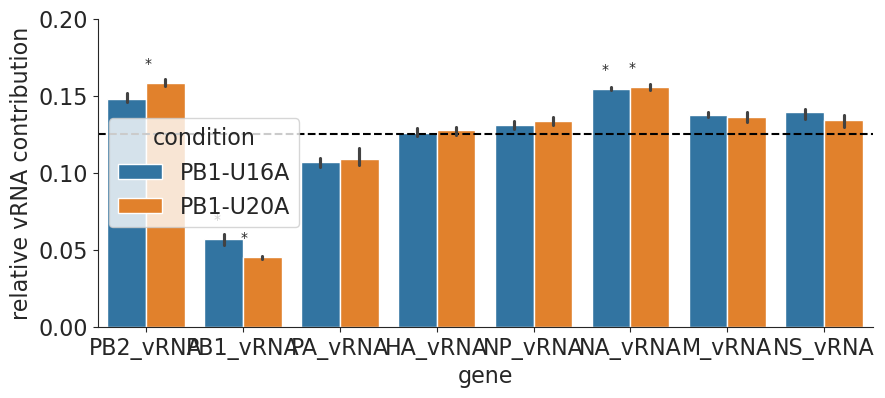

In [4]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
plt.axhline(y=1/8, color = 'k', ls='--')
hue_order = ['PB1-U16A','PB1-U20A']
sns.barplot(y='relative vRNA contribution', x='gene', hue='condition',hue_order=hue_order, data=counts_df,        
                 order=segments, ax=ax)
sns.despine()

plt.ylim(0,0.2)

pvals = []
for gene in segments:
    for condition in hue_order:
        stat, pval  = stats.ttest_1samp(counts_df[(counts_df.gene == gene) & (counts_df.condition == condition)]['relative vRNA contribution'], popmean=1/8)
        pvals += [pval]
qvals = multitest.multipletests(pvals, alpha=0.01, method='fdr_bh', is_sorted=False, returnsorted=False)[0]
for position, gene in enumerate(segments):
    curr = counts_df[counts_df['gene'] == gene]
    bar = 1/len(hue_order)
    for add, condition in enumerate(hue_order):
        if qvals[add + position*2]:
            y = curr[(curr.condition == condition)]['relative vRNA contribution'].mean() + 0.01
            ax.text(position -0.3 + 0.28*add, y, '*', fontsize=10)

plt.savefig(os.path.join('Figures','totalRNAseq', 'relativevRNAabundance.pdf'), format='pdf', bbox_inches = "tight")


In [6]:
U20A = pd.read_csv(os.path.join('Results','totalRNAseq','U20AvU16A.csv'))
BAL = pd.read_csv(os.path.join('Results','totalRNAseq','U20A-BALvU20A.csv'))


In [3]:
inDirectory = os.path.join('Results','totalRNAseq','counts')
counts_df =  []
for file in glob.glob(os.path.join(inDirectory, '*_htseq_counts.tsv')):
    currData = pd.read_csv(file, sep='\t', names = ['gene','count']).iloc[:-5]
    currData = currData[currData.gene.isin(mRNAs)]
    sampleName = '_'.join((os.path.basename(file)).split('_')[0:2])
    currData['replicate'] = sampleName.split('_')[-1]
    condition = sampleName.split('_')[0]
    currData['condition'] = condition
    counts_df += [currData]
counts_df = pd.concat(counts_df).fillna(0)
counts_df['length'] = counts_df.apply(lambda row: mRNALengths[row.gene], axis=1)
counts_df['counts per nt'] = counts_df['count']/counts_df['length']
counts_df = counts_df.merge(counts_df.groupby(['replicate','condition'])['counts per nt'].sum().reset_index().rename(columns = {'counts per nt':'fluSum'}))
counts_df['relative mRNA contribution'] = counts_df['counts per nt']/counts_df.fluSum

In [ ]:
curr

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


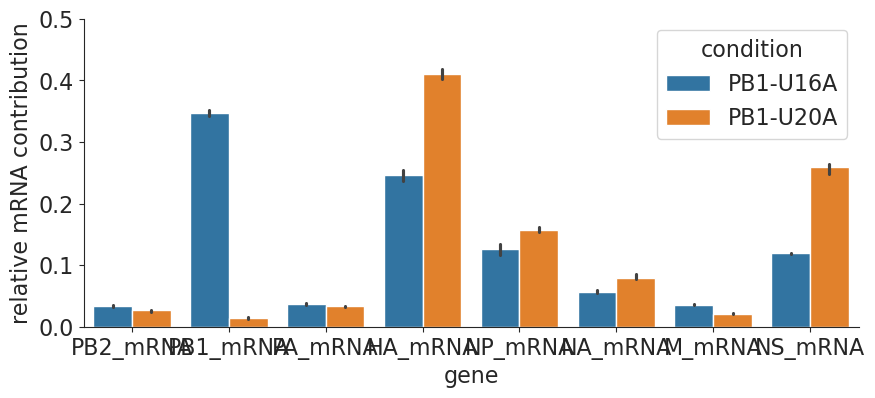

In [23]:
fig, ax = plt.subplots(1,1, figsize=(10,4))
hue_order = ['PB1-U16A','PB1-U20A']
sns.barplot(y='relative mRNA contribution', x='gene', hue='condition',hue_order=hue_order, data=counts_df,        
                 order=mRNAs, ax=ax)
sns.despine()
plt.ylim(0,0.5)

pvals = []
for gene in mRNAs:
    stat, pval  = stats.ttest_ind(counts_df[(counts_df.gene == gene) & (counts_df.condition == 'PB1-U16A')]['relative mRNA contribution'], counts_df[(counts_df.gene == gene) & (counts_df.condition == 'PB1-U20A')]['relative mRNA contribution'])
    pvals += [pval]
qvals = multitest.multipletests(pvals, alpha=0.001, method='fdr_bh', is_sorted=False, returnsorted=False)[0]
for position, gene in enumerate(segments):
    curr = counts_df[counts_df['gene'] == gene]

    if qvals[position]:
        y = curr['relative mRNA contribution'].max() + 0.01
        ax.text(position, y, '*', fontsize=10)
       
plt.savefig(os.path.join('Figures','totalRNAseq', 'relativemRNAabundance.pdf'), format='pdf', bbox_inches = "tight")


In [ ]:
polyA counts, pulled 9nt including polyuracil tract

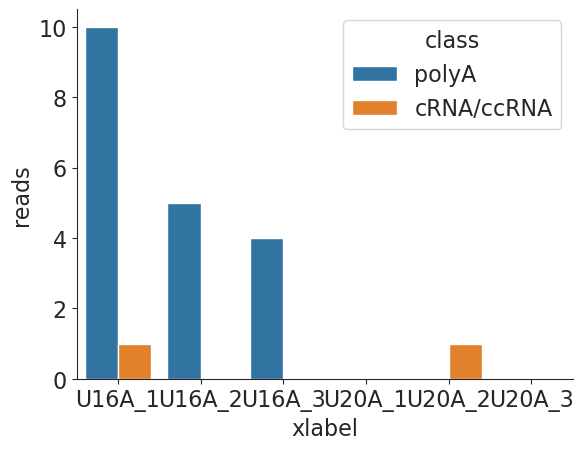

In [34]:
data = pd.read_csv(os.path.join('Results','totalRNAseq','polyACounts.csv')).melt(id_vars = ['strain','replicate'], value_vars = ['polyA','cRNA/ccRNA'], var_name='class', value_name='reads')
data['xlabel'] = data.strain + '_' + data.replicate.astype('str')
order = ['U16A','U20A']
replicates = ['1','2','3']
graphOrder = [strain +'_' + replicate for strain in order for replicate in replicates]
sns.barplot(data=data, x='xlabel', hue='class', y='reads', order=graphOrder, hue_order = ['polyA','cRNA/ccRNA'])
sns. despine()
plt.savefig(os.path.join('Figures','totalRNAseq', 'polyAabundance.pdf'), format='pdf', bbox_inches = "tight")


NT abundance at sites, vRNA only. 

U20A = 776
U16A = 780

In [5]:
data = []
for file in glob.glob(os.path.join('Results','totalRNAseq','alignment','PB1vRNAonly','*_bases.tsv')):
    currFrame = pd.read_csv(file, sep='\t')
    variant, replicate, toss = os.path.basename(file).split('_')
    currFrame['variant'] = variant
    currFrame['replicate'] =replicate
    data += [currFrame]
data = pd.concat(data)
data = data[((data.position == 776) & (data.variant == 'PB1-U20A')) | ((data.position == 780) & (data.variant == 'PB1-U16A'))]
data['not'] = data[['A','G','C','D','I']].sum(axis=1)

In [6]:
data

,segment,position,A,G,C,T,D,I,variant,replicate,not
778,PB1_cRNA,780,4,0,0,119,0,0,PB1-U16A,2,4
765,PB1_cRNA,776,0,0,0,99,0,0,PB1-U20A,3,0
772,PB1_cRNA,780,2,0,2,104,0,0,PB1-U16A,1,4
778,PB1_cRNA,780,0,0,1,123,0,0,PB1-U16A,3,1
765,PB1_cRNA,776,0,0,0,88,0,0,PB1-U20A,1,0
766,PB1_cRNA,776,1,0,0,85,0,0,PB1-U20A,2,1


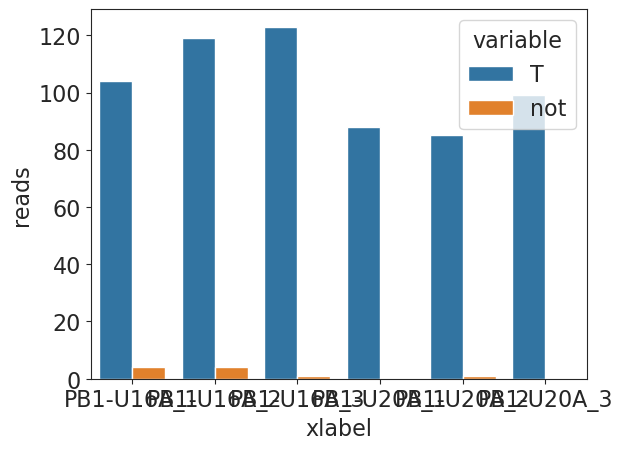

In [2]:
data = []
for file in glob.glob(os.path.join('Results','totalRNAseq','alignment','PB1vRNAonly','*_bases.tsv')):
    currFrame = pd.read_csv(file, sep='\t')
    variant, replicate, toss = os.path.basename(file).split('_')
    currFrame['variant'] = variant
    currFrame['replicate'] =replicate
    data += [currFrame]
data = pd.concat(data)
data = data[((data.position == 776) & (data.variant == 'PB1-U20A')) | ((data.position == 780) & (data.variant == 'PB1-U16A'))]
data['not'] = data[['A','G','C','D','I']].sum(axis=1)
data = data.melt(id_vars = ['variant','replicate'], value_vars = ['T','not'], value_name = 'reads')
data['xlabel'] = data.variant + '_' + data.replicate.astype('str')
order = ['PB1-U16A','PB1-U20A']
replicates = ['1','2','3']
graphOrder = [strain +'_' + replicate for strain in order for replicate in replicates]
sns.barplot(data=data, x='xlabel', hue='variable', y='reads', order=graphOrder, hue_order = ['T','not'])
plt.savefig(os.path.join('Figures','totalRNAseq', 'U_A_retention.pdf'), format='pdf', bbox_inches = "tight")


In [4]:
data.sort_values(['variant','replicate','variable'])

,variant,replicate,variable,reads,xlabel
2,PB1-U16A,1,T,104,PB1-U16A_1
8,PB1-U16A,1,not,4,PB1-U16A_1
0,PB1-U16A,2,T,119,PB1-U16A_2
6,PB1-U16A,2,not,4,PB1-U16A_2
3,PB1-U16A,3,T,123,PB1-U16A_3
9,PB1-U16A,3,not,1,PB1-U16A_3
4,PB1-U20A,1,T,88,PB1-U20A_1
10,PB1-U20A,1,not,0,PB1-U20A_1
5,PB1-U20A,2,T,85,PB1-U20A_2
11,PB1-U20A,2,not,1,PB1-U20A_2


In [40]:
data['majorityVariant'] = data[['A','G','C','T']].idxmax(axis=1)


In [42]:
data['minorityFreq'] = 0.0
data['depth'] = data[['A','G','C','T']].sum(axis=1)
for base in set(data.majorityVariant):
    data.loc[data.majorityVariant == base, 'minorityFreq'] =  1-(data.loc[data.majorityVariant == base, base]/data.loc[data.majorityVariant == base, 'depth'])


In [59]:
''.join(data[(data.replicate == '2') & (data.variant == 'PB1-U16A')].majorityVariant)

'GCGAAAGCAGGCAAACCATTTGAATGGATGTCAATCCGACTTTACTTTTCTTAAAAGTGCCAGCACAAAATGCTATAAGCACAACTTTCCCTTATACTGGAGACCCTCCTTACAGCCATGGGACAGGAACAGGATACACCATGGATACTGTCAACAGGACACATCAGTACTCAGAAAGGGGAAGATGGACAACAAACACCGAAACTGGAGCACCGCAACTCAACCCGATTGATGGGCCACTGCCAGAAGACAATGAACCAAGTGGTTATGCCCAAACAGATTGTGTATTGGAAGCAATGGCCTTCCTTGAGGAATCCCATCCTGGTATCTTTGAGACCTCGTGTCTTGATGCAACCCACTGAACCCATTTGTCAACCATAAAGACATTGAATCAGTGAACAATGCAGTGATAATGCCAGCACATGGTCCAGCCAAAAACATGGAGTATGATGCTGTTGCAACAACACACTCCTGGATCCCCAAAAGAAATCGATCCATCTTGAATACAAGCCAAAGAGGAATACTTGAAGATGAACAAATGTACCAAAAGTGCTGCAACTTATTTGAAAAATTCTTCCCCAGCAGTTCATACAGAAGACCAGTCGGGATATCCAGTATGGTGGAGGCTATGGTTTCCAGAGCCCGAATTGATGCACGAATTGATTTCGAATCTGGAAGGATAAAGAAAGAGGAGTTCACTGAGATCATGAAGATCTGTTCCACCATTGAAGAGCTCAGACGGCAAAAATAGTGAATTTAGCTTGTCCTTCATGAAAAATTGCC'

In [64]:
data[data.position == 647]

,segment,position,A,G,C,T,D,I,variant,replicate,majorityVariant,minorityFreq,depth
645,PB1_cRNA,647,228,5,0,0,0,0,PB1-U16A,2,A,0.021459,233
636,PB1_cRNA,647,185,0,0,0,0,0,PB1-U20A-BAL,2,A,0.000000,185
636,PB1_cRNA,647,197,3,0,0,0,0,PB1-U20A,3,A,0.015000,200
639,PB1_cRNA,647,219,5,0,0,0,0,PB1-U16A,1,A,0.022321,224
645,PB1_cRNA,647,213,2,0,0,0,0,PB1-U16A,3,A,0.009302,215
646,PB1_cRNA,647,157,1,0,0,0,0,PB1-U20A-BAL,3,A,0.006329,158
640,PB1_cRNA,647,177,1,0,0,0,0,PB1-U20A-BAL,1,A,0.005618,178
636,PB1_cRNA,647,210,3,0,0,0,0,PB1-U20A,1,A,0.014085,213
637,PB1_cRNA,647,171,2,0,0,0,0,PB1-U20A,2,A,0.011561,173


In [47]:
data[(data.minorityFreq > 0.02) & (data.depth > 50)]

,segment,position,A,G,C,T,D,I,variant,replicate,majorityVariant,minorityFreq,depth
347,PB1_cRNA,349,0,90,0,2,0,0,PB1-U16A,2,G,0.021739,92
374,PB1_cRNA,376,73,2,0,0,0,0,PB1-U16A,2,A,0.026667,75
384,PB1_cRNA,386,2,0,71,0,0,0,PB1-U16A,2,C,0.027397,73
394,PB1_cRNA,396,2,75,0,0,0,0,PB1-U16A,2,G,0.025974,77
411,PB1_cRNA,413,90,2,0,0,0,0,PB1-U16A,2,A,0.021739,92
645,PB1_cRNA,647,228,5,0,0,0,0,PB1-U16A,2,A,0.021459,233
778,PB1_cRNA,780,4,0,0,119,0,0,PB1-U16A,2,T,0.032520,123
549,PB1_cRNA,560,0,0,81,2,0,0,PB1-U20A,3,C,0.024096,83
639,PB1_cRNA,647,219,5,0,0,0,0,PB1-U16A,1,A,0.022321,224
772,PB1_cRNA,780,2,0,2,104,0,0,PB1-U16A,1,T,0.037037,108


In [16]:
 pd.read_csv(os.path.join('Results','totalRNAseq','polyACounts.csv')).melt(id_vars = ['strain','replicate'], value_vars = ['polyA','cRNA/ccRNA'], var_name='class', value_name='reads')

,strain,replicate,class,reads
0,U16A,1,polyA,10
1,U16A,2,polyA,5
2,U16A,3,polyA,4
3,U20A,1,polyA,0
4,U20A,2,polyA,0
5,U20A,3,polyA,0
6,U16A,1,cRNA/ccRNA,1
7,U16A,2,cRNA/ccRNA,0
8,U16A,3,cRNA/ccRNA,0
9,U20A,1,cRNA/ccRNA,0


In [8]:
gene

'NS_vRNA'